# Transformers and flow matching from scratch, in JAX

First of all, let's build a transformer from scratch, and teach it to do regression **in context**: every training
example is a *different* function, and the network only sees a handful of noisy points from it. Nothing about
any one function can actually be stored in the weights, but the model has to work it out from its input.

In the second half, we will reuse the same network as the velocity field of a **flow matching** model, and draw from the posterior
of functions that are consistent with the data.

The functions are drawn from a Gaussian process with a random lengthscale, so the best possible answer is known
exactly. It will be given by `gp_posterior`.

Acknowledgement: I used ChatGPT (OpenAI) to help explain concepts, debug and improve my code, and suggest implementations and visualizations. I reviewed and modified its suggestions and verified the final code and results myself.

In [1]:
# !pip install -q jax jaxlib matplotlib

import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

print("jax", jax.__version__, "| devices:", jax.devices())

jax 0.4.38 | devices: [CpuDevice(id=0)]


In [2]:
# Uncomment if Optax is not installed.
# %pip install optax

import optax

/opt/anaconda3/envs/ml4s/lib/python3.11/pty.py:89: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


  Using cached jax-0.10.2-py3-none-any.whl.metadata (13 kB)
INFO: pip is looking at multiple versions of optax to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of chex to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [optax]32m3/4 [optax]
Note: you may need to restart the kernel to use updated packages.


## The data


In [3]:
X_MAX = 2.0
NOISE_STD = 0.05
ELL_MIN, ELL_MAX = 0.2, 1.0


def rbf(x1, x2, ell):
    """x1: (b, n), x2: (b, m), ell: (b,) -> (b, n, m)"""
    
    """
    Compute the radial basis function (RBF) kernel:

        k(x, x') = exp(-(x - x')^2 / (2 * ell^2))

    The kernel specifies the covariance between function values at
    different input locations. The lengthscale ell controls how
    rapidly the correlation decays with distance; larger values
    correspond to smoother, more slowly varying functions.

    Args:
        x1: Input locations, shape (batch, n).
        x2: Input locations, shape (batch, m).
        ell: Kernel lengthscales, shape (batch,).

    Returns:
        Kernel matrices of shape (batch, n, m).
    """
    return jnp.exp(-0.5 * (x1[:, :, None] - x2[:, None, :]) ** 2 / ell[:, None, None] ** 2)


def sample_tasks(key, batch, n_ctx, n_tgt=32, ell=None, x_tgt=None):
    """Draw `batch` random functions, each observed (with noise) at n_ctx context and n_tgt target points.
    Returns xc, yc: (batch, n_ctx)   xt, yt: (batch, n_tgt)   ell: (batch,)"""

    """
    Generate independent Gaussian process (GP) regression tasks.

    Each task samples a function from a zero-mean GP with an RBF
    kernel and adds independent Gaussian observation noise.
    Context points provide observed input-output pairs, while
    target points specify locations where predictions are required.

    Args:
        key: JAX random key.
        batch: Number of independent regression tasks.
        n_ctx: Number of context observations per task.
        n_tgt: Number of target points per task.
        ell: Optional fixed lengthscale(s); sampled if None.
        x_tgt: Optional predefined target locations.

    Returns:
        xc, yc: Context inputs and observations, (batch, n_ctx).
        xt, yt: Target inputs and observations, (batch, n_tgt).
        ell: Lengthscale for each task, (batch,).
    """
    k_ell, k_xc, k_xt, k_y = jax.random.split(key, 4)
    if ell is None:
        ell = jnp.exp(jax.random.uniform(k_ell, (batch,), minval=np.log(ELL_MIN), maxval=np.log(ELL_MAX)))
    ell = jnp.broadcast_to(jnp.asarray(ell, jnp.float32), (batch,))
    xc = jax.random.uniform(k_xc, (batch, n_ctx), minval=-X_MAX, maxval=X_MAX)
    if x_tgt is None:
        xt = jax.random.uniform(k_xt, (batch, n_tgt), minval=-X_MAX, maxval=X_MAX)
    else:
        xt = jnp.broadcast_to(x_tgt, (batch, x_tgt.shape[-1]))
    x = jnp.concatenate([xc, xt], axis=1)
    K = rbf(x, x, ell) + (NOISE_STD**2 + 1e-5) * jnp.eye(x.shape[1])
    y = jnp.einsum("bij,bj->bi", jnp.linalg.cholesky(K), jax.random.normal(k_y, x.shape))

    # Target observations are used to evaluate predictions, but are
    # not provided to the transformer as input.
    return xc, y[:, :n_ctx], xt, y[:, n_ctx:], ell


def gp_posterior(xc, yc, xt, ell):
    """Exact GP prediction at xt given (xc, yc), if you knew the lengthscale.
    Returns mean: (b, n_tgt), cov: (b, n_tgt, n_tgt)"""

    """
    Compute the exact GP posterior predictive distribution at xt,
    conditioned on the context observations (xc, yc).

    Assumes the RBF kernel, observation noise, and true lengthscale
    are known. Returns the predictive mean and covariance, providing
    an ideal reference for evaluating the learned regression model.

    Args:
        xc, yc: Context inputs and observations.
        xt: Target input locations.
        ell: Known GP lengthscale(s).

    Returns:
        mean: Posterior predictive mean, (batch, n_tgt).
        cov: Posterior predictive covariance, (batch, n_tgt, n_tgt).
    """
    ell = jnp.broadcast_to(jnp.asarray(ell, jnp.float32), (xc.shape[0],))
    Kcc = rbf(xc, xc, ell) + NOISE_STD**2 * jnp.eye(xc.shape[1])
    Ktc = rbf(xt, xc, ell)
    Ktt = rbf(xt, xt, ell) + NOISE_STD**2 * jnp.eye(xt.shape[1])
    A = jnp.linalg.solve(Kcc, jnp.swapaxes(Ktc, 1, 2))
    mean = jnp.einsum("bct,bc->bt", A, yc)
    return mean, Ktt - Ktc @ A


xc, yc, xt, yt, ell = sample_tasks(jax.random.key(0), batch=1000, n_ctx=10)
mean, cov = gp_posterior(xc, yc, xt, ell)

print(f"target variance               : {float(yt.var()):.4f}")   # predict 0 everywhere
print(f"GP error, 10 points, true ell : {float(((mean - yt) ** 2).mean()):.4f}")   # the best you can do

target variance               : 0.9896
GP error, 10 points, true ell : 0.1497


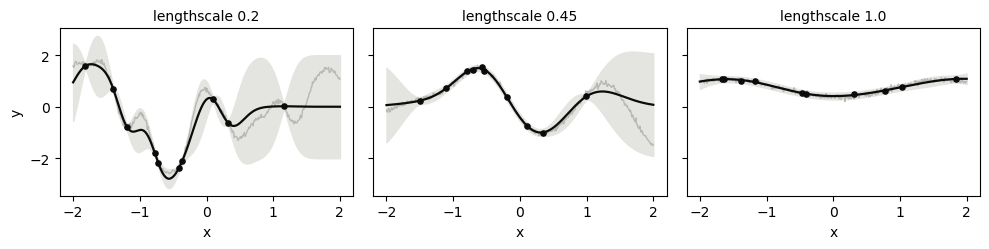

In [4]:
grid = jnp.linspace(-X_MAX, X_MAX, 400)
fig, axes = plt.subplots(1, 3, figsize=(10, 2.6), sharey=True)
for ax, ell_, key in zip(axes, [0.2, 0.45, 1.0], jax.random.split(jax.random.key(1), 3)):
    xc, yc, xt, yt, _ = sample_tasks(key, 1, n_ctx=10, ell=ell_, x_tgt=grid)
    mean, cov = gp_posterior(xc, yc, grid[None], ell_)
    std = jnp.sqrt(jnp.diagonal(cov[0]))
    ax.fill_between(np.array(grid), np.array(mean[0] - 2 * std), np.array(mean[0] + 2 * std), color="#e4e4e0")
    ax.plot(np.array(grid), np.array(yt[0]), color="#b8b8b4", lw=1)
    ax.plot(np.array(grid), np.array(mean[0]), color="#0b0b0b", lw=1.6)
    ax.scatter(np.array(xc[0]), np.array(yc[0]), s=14, color="#0b0b0b", zorder=3)
    ax.set_title(f"lengthscale {ell_}", fontsize=10); ax.set_xlabel("x")
axes[0].set_ylabel("y"); plt.tight_layout(); plt.show()

---
## 1. Attention, MLP, and transformer block

Every observed point becomes a token `(x, y, 1)`; every point where you want a prediction is also  a token
`(x, 0, 0)`.

Write multi-head self-attention, `attention(params, h, mask)`, where `mask[i, j]` says whether token `i` may look
at token `j`. Then a transformer block: layer norm, attention, residual, MLP, residual.

Choose the mask.  What are targets allowed to look at? should they receive information from other targets?

In [5]:
def init_attention(key, d_model=64):
    """
    Initialize the learnable weight matrices for multi-head attention
    using Xavier (Glorot) normal initialization.

    Args:
        key: JAX random key.
        d_model: Token embedding dimension.

    Returns:
        Dictionary containing Wq, Wk, Wv, and Wo,
        each of shape (d_model, d_model).
    """
    keys = jax.random.split(key, 4)

    def init_weight(k):
        return jax.random.normal(k, (d_model, d_model)) / jnp.sqrt(d_model) # Xavier normal initialization, keeps the scale under control

    return {
        "Wq": init_weight(keys[0]),
        "Wk": init_weight(keys[1]),
        "Wv": init_weight(keys[2]),
        "Wo": init_weight(keys[3]),
    }


def attention(params, h, mask, n_heads=4):
    """
    Apply multi-head scaled dot-product self-attention.

    Args:
        params: Dictionary containing Wq, Wk, Wv, and Wo.
        h: Input embeddings, shape (batch, n_tokens, d_model).
        mask: Boolean attention mask, shape (n_tokens, n_tokens).
              mask[i, j] is True if token i can attend to token j.
        n_heads: Number of attention heads.

    Returns:
        Updated embeddings, shape (batch, n_tokens, d_model).
    """
    batch, n_tokens, d_model = h.shape
    d_head = d_model // n_heads

    # Project input embeddings into queries, keys, and values.
    Q = h @ params["Wq"]
    K = h @ params["Wk"]
    V = h @ params["Wv"]

    # Split the embedding dimension into attention heads.
    # (batch, n_tokens, d_model)
    # -> (batch, n_heads, n_tokens, d_head)
    def split_heads(x):
        x = x.reshape(batch, n_tokens, n_heads, d_head)
        return x.transpose(0, 2, 1, 3)

    Q = split_heads(Q)
    K = split_heads(K)
    V = split_heads(V)

    # Compute scaled query-key similarity scores.
    scores = Q @ jnp.swapaxes(K, -1, -2) # transpose and swapaxes are both to make the matrix multiplication make sense
    scores = scores / jnp.sqrt(d_head)

    # Prevent attention to disallowed tokens.
    scores = jnp.where(mask[None, None, :, :], scores, -1e9)

    # Normalize attention weights across key positions.
    weights = jax.nn.softmax(scores, axis=-1)

    # Compute weighted sums of value vectors.
    out = weights @ V

    # Concatenate attention heads.
    out = out.transpose(0, 2, 1, 3)
    out = out.reshape(batch, n_tokens, d_model)

    # Apply the final output projection.
    return out @ params["Wo"]


In [6]:
# Test attention
batch = 8
n_ctx = 10
n_tgt = 32
n_tokens = n_ctx + n_tgt
d_model = 64

# Random token embeddings
h = jax.random.normal(
    jax.random.key(1),
    (batch, n_tokens, d_model)
)

# Attention mask:
# Contexts attend to contexts.
# Each target attends to contexts and itself.
mask = jnp.zeros((n_tokens, n_tokens), dtype=bool)
mask = mask.at[:, :n_ctx].set(True)
mask = mask.at[jnp.arange(n_ctx, n_tokens),
               jnp.arange(n_ctx, n_tokens)].set(True)

# Apply multi-head attention
attn_params = init_attention(jax.random.key(0))
out = attention(attn_params, h, mask, n_heads=4)

print("Input shape :", h.shape)
print("Output shape:", out.shape)


Input shape : (8, 42, 64)
Output shape: (8, 42, 64)


In [7]:
def init_layer_norm(d_model=64):
    """
    Initialize the learnable LayerNorm parameters.

    Returns:
        gamma: Scaling parameters, shape (d_model,).
        beta: Shifting parameters, shape (d_model,).
    """
    return {
        "gamma": jnp.ones((d_model,)),
        "beta": jnp.zeros((d_model,)) # initiallly only normalization is performed
    }


def layer_norm(params, h, eps=1e-5):
    """
    Apply Layer Normalization independently to each token.

    Args:
        params: Dictionary containing gamma and beta.
        h: Input embeddings, shape (batch, n_tokens, d_model).
        eps: Small constant for numerical stability.

    Returns:
        Normalized embeddings with the same shape as h.
    """
    mean = jnp.mean(h, axis=-1, keepdims=True)
    var = jnp.mean((h - mean) ** 2, axis=-1, keepdims=True)

    h_norm = (h - mean) / jnp.sqrt(var + eps)

    return params["gamma"] * h_norm + params["beta"]


In [8]:
# Test layer_norm
ln_params = init_layer_norm(d_model=64)

h = jax.random.normal(
    jax.random.key(0),
    (8, 42, 64)
) * 5 + 10

h_norm = layer_norm(ln_params, h)

print("Input shape :", h.shape)
print("Output shape:", h_norm.shape)

print("Mean before normalization :", h[0, 0].mean())
print("Mean after normalization  :", h_norm[0, 0].mean())

print("Variance before normalization :", h[0, 0].var())
print("Variance after normalization  :", h_norm[0, 0].var())

Input shape : (8, 42, 64)
Output shape: (8, 42, 64)
Mean before normalization : 10.274963
Mean after normalization  : -1.0803342e-07
Variance before normalization : 18.460438
Variance after normalization  : 0.9999995


In [9]:
def init_mlp(key, d_model=64, d_hidden=256):
    """
    Initialize the parameters of a two-layer feed-forward MLP.

    Args:
        key: JAX random key.
        d_model: Input and output embedding dimension.
        d_hidden: Hidden layer dimension.

    Returns:
        Dictionary containing W1, b1, W2, and b2.
    """
    k1, k2 = jax.random.split(key, 2)

    def init_weight(k, fan_in, fan_out):
        std = jnp.sqrt(2.0 / (fan_in + fan_out))
        return jax.random.normal(k, (fan_in, fan_out)) * std

    return {
        "W1": init_weight(k1, d_model, d_hidden),
        "b1": jnp.zeros((d_hidden,)),
        "W2": init_weight(k2, d_hidden, d_model),
        "b2": jnp.zeros((d_model,))
    }


def mlp(params, h):
    """
    Apply a two-layer feed-forward MLP independently to each token.

    Args:
        params: Dictionary containing W1, b1, W2, and b2.
        h: Input embeddings, shape (batch, n_tokens, d_model).

    Returns:
        Transformed embeddings with the same shape as h.
    """
    # Expand the embedding dimension.
    h = h @ params["W1"] + params["b1"]

    # Apply nonlinear activation.
    h = jax.nn.gelu(h)

    # Project back to the original embedding dimension.
    h = h @ params["W2"] + params["b2"]

    return h


In [10]:
# Test mlp
mlp_params = init_mlp(jax.random.key(2))

h = jax.random.normal(
    jax.random.key(3),
    (8, 42, 64)
)

out = mlp(mlp_params, h)

print("Input shape :", h.shape)
print("Output shape:", out.shape)


Input shape : (8, 42, 64)
Output shape: (8, 42, 64)


In [11]:
def init_transformer_block(key, d_model=64, d_hidden=256):
    """
    Initialize the parameters of a pre-norm transformer block.

    Args:
        key: JAX random key.
        d_model: Token embedding dimension.
        d_hidden: Hidden dimension of the feed-forward MLP.

    Returns:
        Dictionary containing parameters for two LayerNorms,
        multi-head attention, and the feed-forward MLP.
    """
    k_attn, k_mlp = jax.random.split(key, 2)

    return {
        "ln1": init_layer_norm(d_model),
        "attn": init_attention(k_attn, d_model),
        "ln2": init_layer_norm(d_model),
        "mlp": init_mlp(k_mlp, d_model, d_hidden)
    }


def transformer_block(params, h, mask, n_heads=4):
    """
    Apply a pre-norm transformer block consisting of multi-head
    self-attention and a feed-forward MLP, each with a residual
    connection.

    Args:
        params: Transformer block parameters.
        h: Input embeddings, shape (batch, n_tokens, d_model).
        mask: Boolean attention mask, shape (n_tokens, n_tokens).
        n_heads: Number of attention heads.

    Returns:
        Updated embeddings with the same shape as h.
    """
    # Multi-head self-attention with pre-normalization and residual.
    h = h + attention(
        params["attn"],
        layer_norm(params["ln1"], h),
        mask,
        n_heads
    )

    # Feed-forward MLP with pre-normalization and residual.
    h = h + mlp(
        params["mlp"],
        layer_norm(params["ln2"], h)
    )

    return h


In [12]:
# Test transformer_block
# Initialize transformer block.
block_params = init_transformer_block(jax.random.key(0))

# Generate random input embeddings.
batch, n_ctx, n_tgt, d_model = 8, 10, 32, 64
n_tokens = n_ctx + n_tgt

h = jax.random.normal(
    jax.random.key(1),
    (batch, n_tokens, d_model)
)

# Create the attention mask.
mask = jnp.zeros((n_tokens, n_tokens), dtype=bool)
mask = mask.at[:, :n_ctx].set(True)
mask = mask.at[jnp.arange(n_ctx, n_tokens),
               jnp.arange(n_ctx, n_tokens)].set(True)

# Apply transformer block.
out = transformer_block(block_params, h, mask)

print("Input shape :", h.shape)
print("Output shape:", out.shape)
print("All outputs finite:", bool(jnp.all(jnp.isfinite(out))))


Input shape : (8, 42, 64)
Output shape: (8, 42, 64)
All outputs finite: True


---
## 2. The transformer

Embed the tokens (a small MLP is fine), stack transformer blocks, and read out a mean and a log-variance at each target.
We will assume a Gaussian negative log-likelihood during training. Some reasonable numbers are width 64, 4 heads, 4 layers.

Each step: get a batch of functions, with a random number of context points between 3 and 30, and 30'ish targets as well. 
Feel free to use jax libraries for the optimiser and weight updates (no need to use your solution from the previous tutorial!). 
The number of context points changes the shapes, so `jax.jit` recompiles once per value. That's fine, otherwise you'd need to add some padding

In [13]:
def make_tokens(xc, yc, xt):
    """
    Construct context and target tokens for in-context regression.

    Context tokens: (x_c, y_c, 1).
    Target tokens:  (x_t, 0, 0).

    0 and 1 are to distinguish the two types of tokens. Note that yt is not used in the target tokens.

    Args:
        xc, yc: Context inputs and observations, (batch, n_ctx).
        xt: Target input locations, (batch, n_tgt).

    Returns:
        Tokens of shape (batch, n_ctx + n_tgt, 3).
    """
    ctx = jnp.stack(
        [xc, yc, jnp.ones_like(xc)], axis=-1
    )

    tgt = jnp.stack(
        [xt, jnp.zeros_like(xt), jnp.zeros_like(xt)],
        axis=-1
    )

    return jnp.concatenate([ctx, tgt], axis=1)


In [14]:
def init_embedding(key, d_model=64):
    """
    Initialize a two-layer input embedding MLP.

    Maps 3-dimensional tokens to d_model-dimensional embeddings.

    Args:
        key: JAX random key.
        d_model: Output embedding dimension.

    Returns:
        Dictionary containing W1, b1, W2, and b2.
    """
    k1, k2 = jax.random.split(key, 2)

    def init_weight(k, fan_in, fan_out):
        std = jnp.sqrt(2.0 / (fan_in + fan_out))
        return jax.random.normal(k, (fan_in, fan_out)) * std # Xavier (Glorot) normal initialization again

    return {
        "W1": init_weight(k1, 3, d_model),
        "b1": jnp.zeros((d_model,)),
        "W2": init_weight(k2, d_model, d_model),
        "b2": jnp.zeros((d_model,))
    }


def embed_tokens(params, tokens):
    """
    Embed context and target tokens using a two-layer MLP.

    Args:
        params: Input embedding MLP parameters.
        tokens: Input tokens, shape (batch, n_tokens, 3).

    Returns:
        Embeddings, shape (batch, n_tokens, d_model).
    """
    return mlp(params, tokens)


In [15]:
# Test input embedding
# Generate a batch of GP regression tasks.
xc, yc, xt, yt, ell = sample_tasks(
    jax.random.key(0),
    batch=8,
    n_ctx=10,
    n_tgt=32
)

# Construct context and target tokens.
tokens = make_tokens(xc, yc, xt)

# Initialize and apply the embedding MLP.
embed_params = init_embedding(jax.random.key(1))
h = embed_tokens(embed_params, tokens)

print("Context shape  :", xc.shape)
print("Target shape   :", xt.shape)
print("Token shape    :", tokens.shape)
print("Embedding shape:", h.shape)


Context shape  : (8, 10)
Target shape   : (8, 32)
Token shape    : (8, 42, 3)
Embedding shape: (8, 42, 64)


In [16]:
def init_output_head(key, d_model=64):
    """
    Initialize the output projection for Gaussian regression.

    Maps each target embedding to a predictive mean and
    log-variance.

    Args:
        key: JAX random key.
        d_model: Transformer embedding dimension.

    Returns:
        Dictionary containing W and b.
    """
    std = jnp.sqrt(2.0 / (d_model + 2)) # Xavier (Glorot) normal initialization: W_{ij} ~ N(0, 2 / (d_{in} + d_{out}))

    return {
        "W": jax.random.normal(key, (d_model, 2)) * std,
        "b": jnp.zeros((2,))
    }


In [17]:
def output_head(params, h, n_ctx):
    """
    Predict the mean and log-variance at each target location.

    Args:
        params: Output projection parameters.
        h: Transformer embeddings, (batch, n_tokens, d_model).
        n_ctx: Number of context tokens.

    Returns:
        mean: Predicted means, (batch, n_tgt).
        log_var: Predicted log-variances, (batch, n_tgt).
    """
    # Extract target embeddings.
    h_tgt = h[:, n_ctx:, :]

    # Project each target embedding to two scalar outputs.
    out = h_tgt @ params["W"] + params["b"]

    mean = out[..., 0]
    log_var = out[..., 1]

    return mean, log_var


In [18]:
# Test output head implementation
# Initialize output head.
head_params = init_output_head(jax.random.key(4))

# Simulate embeddings produced by the transformer.
batch, n_ctx, n_tgt, d_model = 8, 10, 32, 64

h = jax.random.normal(
    jax.random.key(5),
    (batch, n_ctx + n_tgt, d_model)
)

# Predict mean and log-variance.
mean, log_var = output_head(head_params, h, n_ctx)

print("Mean shape        :", mean.shape)
print("Log-variance shape:", log_var.shape)

# Convert log-variance to standard deviation.
std = jnp.exp(0.5 * log_var)

print("Standard deviation shape:", std.shape)


Mean shape        : (8, 32)
Log-variance shape: (8, 32)
Standard deviation shape: (8, 32)


In [19]:
def init_transformer(key, d_model=64, n_heads=4, n_layers=4, d_hidden=256):
    """
    Initialize a transformer for in-context GP regression.

    Args:
        key: JAX random key.
        d_model: Token embedding dimension.
        n_heads: Number of attention heads.
        n_layers: Number of transformer blocks.
        d_hidden: Hidden dimension of the feed-forward MLP.

    Returns:
        Dictionary containing the input embedding, transformer
        blocks, and output head parameters.
    """
    assert d_model % n_heads == 0

    keys = jax.random.split(key, n_layers + 2)

    return {
        "embed": init_embedding(keys[0], d_model),
        "blocks": [
            init_transformer_block(keys[i + 1], d_model, d_hidden)
            for i in range(n_layers)
        ], # each block has its own learnable weights
        "head": init_output_head(keys[-1], d_model)
    }


In [20]:
def transformer(params, xc, yc, xt, n_heads=4):
    """
    Predict the mean and log-variance at target locations
    using a transformer conditioned on context observations.

    Args:
        params: Complete transformer parameters.
        xc, yc: Context inputs and observations, (batch, n_ctx).
        xt: Target input locations, (batch, n_tgt).
        n_heads: Number of attention heads.

    Returns:
        mean: Predicted target means, (batch, n_tgt).
        log_var: Predicted target log-variances, (batch, n_tgt).
    """
    n_ctx = xc.shape[1]
    n_tgt = xt.shape[1]
    n_tokens = n_ctx + n_tgt

    # Construct context (x, y, 1) and target (x, 0, 0) tokens.
    tokens = make_tokens(xc, yc, xt)

    # Embed each token into a d_model-dimensional vector.
    h = embed_tokens(params["embed"], tokens)

    # Construct the attention mask.
    # All tokens may attend to context tokens.
    # Each target may additionally attend to itself.
    mask = jnp.zeros((n_tokens, n_tokens), dtype=bool)
    mask = mask.at[:, :n_ctx].set(True)

    tgt_idx = jnp.arange(n_ctx, n_tokens)
    mask = mask.at[tgt_idx, tgt_idx].set(True)

    # Apply successive transformer blocks.
    for block_params in params["blocks"]:
        h = transformer_block(block_params, h, mask, n_heads)

    # Predict mean and log-variance at target locations.
    mean, log_var = output_head(params["head"], h, n_ctx)

    return mean, log_var


In [21]:
# Test the complete model
# Initialize the transformer.
params = init_transformer(
    jax.random.key(0),
    d_model=64,
    n_heads=4,
    n_layers=4,
    d_hidden=256
)

# Generate a batch of GP regression tasks.
xc, yc, xt, yt, ell = sample_tasks(
    jax.random.key(1),
    batch=8,
    n_ctx=10,
    n_tgt=32
)

# Run the forward pass.
mean, log_var = transformer(params, xc, yc, xt)

print("Predicted mean shape:", mean.shape)
print("Predicted log-variance shape:", log_var.shape)
print("All outputs finite:",
      bool(jnp.all(jnp.isfinite(mean)) &
           jnp.all(jnp.isfinite(log_var))))


Predicted mean shape: (8, 32)
Predicted log-variance shape: (8, 32)
All outputs finite: True


In [22]:
# Check permutation invariance
# Original predictions.
mean1, log_var1 = transformer(params, xc, yc, xt)

# Shuffle context points using the same permutation for x and y.
perm = jax.random.permutation(jax.random.key(2), xc.shape[1])

xc_shuffled = xc[:, perm]
yc_shuffled = yc[:, perm]

# Predictions after shuffling.
mean2, log_var2 = transformer(
    params, xc_shuffled, yc_shuffled, xt
)

print("Maximum mean difference:",
      float(jnp.max(jnp.abs(mean1 - mean2))))

print("Maximum log-variance difference:",
      float(jnp.max(jnp.abs(log_var1 - log_var2))))


Maximum mean difference: 2.384185791015625e-06
Maximum log-variance difference: 3.4570693969726562e-06


In [23]:
def gaussian_nll(mean, log_var, y):
    """
    Compute the mean Gaussian negative log-likelihood.

    Args:
        mean: Predicted means, shape (batch, n_tgt).
        log_var: Predicted log-variances, shape (batch, n_tgt).
        y: Observed target values, shape (batch, n_tgt).

    Returns:
        Scalar mean negative log-likelihood.
    """
    nll = 0.5 * (
        jnp.log(2.0 * jnp.pi)
        + log_var
        + (y - mean) ** 2 * jnp.exp(-log_var)
    )

    return jnp.mean(nll)


In [24]:
def loss_fn(params, xc, yc, xt, yt):
    """
    Compute the Gaussian NLL loss for the transformer.
    """
    mean, log_var = transformer(params, xc, yc, xt)

    return gaussian_nll(mean, log_var, yt)


In [32]:
# Model configuration
d_model = 64
n_heads = 4
n_layers = 4
d_hidden = 256

# Training configuration
learning_rate = 3e-4
batch_size = 32
n_steps = 5000
n_tgt = 32

# Initialize model parameters.
key = jax.random.key(0)
key, init_key = jax.random.split(key)

params = init_transformer(
    init_key,
    d_model=d_model,
    n_heads=n_heads,
    n_layers=n_layers,
    d_hidden=d_hidden
)

# Initialize Adam optimizer.
optimizer = optax.adam(learning_rate)
opt_state = optimizer.init(params)


In [33]:
@jax.jit
def train_step(params, opt_state, xc, yc, xt, yt):
    """
    Perform one transformer training step using Adam.

    Args:
        params: Current transformer parameters.
        opt_state: Current Adam optimizer state.
        xc, yc: Context inputs and observations.
        xt, yt: Target inputs and observations.

    Returns:
        Updated model parameters, optimizer state, and loss.
    """
    # Calculate the loss and its gradients.
    loss, grads = jax.value_and_grad(loss_fn)(
        params, xc, yc, xt, yt
    )

    # Calculate Adam parameter updates.
    updates, opt_state = optimizer.update(
        grads, opt_state, params
    )

    # Apply updates to the model parameters.
    params = optax.apply_updates(params, updates)

    return params, opt_state, loss


In [34]:
# Store the training loss for visualization.
loss_history = []

for step in range(n_steps):

    # Generate independent random keys.
    key, k_ctx, k_data = jax.random.split(key, 3)

    # Randomly choose the number of context points (3 to 30).
    n_ctx = int(jax.random.randint(k_ctx, (), 3, 31))

    # Sample a new batch of GP regression tasks.
    xc, yc, xt, yt, ell = sample_tasks(
        k_data,
        batch=batch_size,
        n_ctx=n_ctx,
        n_tgt=n_tgt
    )

    # Perform one Adam optimization step.
    params, opt_state, loss = train_step(
        params, opt_state, xc, yc, xt, yt
    )

    # Record the training loss.
    loss_history.append(float(loss))

    # Print progress every 100 steps.
    if (step + 1) % 100 == 0:
        print(
            f"Step {step+1:4d}/{n_steps} | "
            f"n_ctx = {n_ctx:2d} | "
            f"Loss = {float(loss):.4f}"
        )


Step  100/5000 | n_ctx = 16 | Loss = 1.1554
Step  200/5000 | n_ctx = 21 | Loss = 1.1711
Step  300/5000 | n_ctx =  6 | Loss = 1.1060
Step  400/5000 | n_ctx = 20 | Loss = 1.0410
Step  500/5000 | n_ctx =  8 | Loss = 1.0915
Step  600/5000 | n_ctx =  8 | Loss = 1.2131
Step  700/5000 | n_ctx = 22 | Loss = 0.7856
Step  800/5000 | n_ctx = 23 | Loss = 0.7718
Step  900/5000 | n_ctx = 23 | Loss = 0.8390
Step 1000/5000 | n_ctx = 20 | Loss = 0.9265
Step 1100/5000 | n_ctx = 27 | Loss = 0.9004
Step 1200/5000 | n_ctx =  7 | Loss = 0.8723
Step 1300/5000 | n_ctx = 10 | Loss = 0.8231
Step 1400/5000 | n_ctx =  9 | Loss = 0.8859
Step 1500/5000 | n_ctx = 17 | Loss = 0.5090
Step 1600/5000 | n_ctx = 13 | Loss = 0.5604
Step 1700/5000 | n_ctx =  9 | Loss = 0.6117
Step 1800/5000 | n_ctx = 24 | Loss = 0.1302
Step 1900/5000 | n_ctx = 18 | Loss = 0.4034
Step 2000/5000 | n_ctx = 21 | Loss = 0.2969
Step 2100/5000 | n_ctx = 21 | Loss = 0.5145
Step 2200/5000 | n_ctx = 18 | Loss = 0.4081
Step 2300/5000 | n_ctx = 26 | Lo

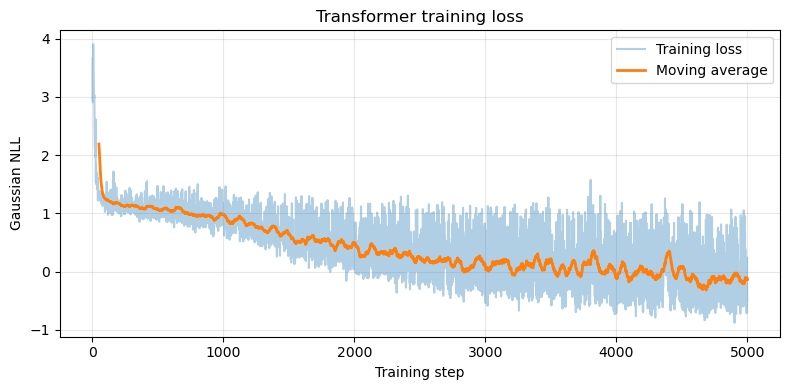

In [35]:
plt.figure(figsize=(8, 4))

plt.plot(
    np.arange(1, n_steps + 1),
    loss_history,
    alpha=0.35,
    label="Training loss"
)

# Moving average for clearer visualization.
window = 50
if len(loss_history) >= window:
    smoothed = np.convolve(
        loss_history,
        np.ones(window) / window,
        mode="valid"
    )

    plt.plot(
        np.arange(window, n_steps + 1),
        smoothed,
        linewidth=2,
        label="Moving average"
    )

plt.xlabel("Training step")
plt.ylabel("Gaussian NLL")
plt.title("Transformer training loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [36]:
# Generate independent test tasks.
key, test_key = jax.random.split(key)

xc, yc, xt, yt, ell = sample_tasks(
    test_key,
    batch=256,
    n_ctx=10,
    n_tgt=32
)

# Transformer predictions.
pred_mean, pred_log_var = transformer(
    params, xc, yc, xt
)

# Exact GP predictions with the true lengthscale.
gp_mean, gp_cov = gp_posterior(
    xc, yc, xt, ell
)

# Compare prediction errors.
transformer_mse = jnp.mean((pred_mean - yt) ** 2)
gp_mse = jnp.mean((gp_mean - yt) ** 2)
zero_mse = jnp.mean(yt ** 2)

print(f"Zero predictor MSE : {float(zero_mse):.4f}")
print(f"Transformer MSE    : {float(transformer_mse):.4f}")
print(f"Exact GP MSE       : {float(gp_mse):.4f}")


Zero predictor MSE : 1.0168
Transformer MSE    : 0.2294
Exact GP MSE       : 0.1583


In [37]:
# Generate three independent GP regression tasks.
n_examples = 3
n_ctx = 10

# Dense grid for visualization.
x_grid = jnp.linspace(-X_MAX, X_MAX, 200)

xc, yc, xt, yt, ell = sample_tasks(
    jax.random.key(42),
    batch=n_examples,
    n_ctx=n_ctx,
    x_tgt=x_grid
)

# Transformer predictions.
pred_mean, pred_log_var = transformer(
    params, xc, yc, xt
)

pred_std = jnp.exp(0.5 * pred_log_var)

# Exact GP posterior using the true lengthscale.
gp_mean, gp_cov = gp_posterior(
    xc, yc, xt, ell
)

# Extract marginal standard deviations.
gp_std = jnp.sqrt(
    jnp.maximum(
        jnp.diagonal(gp_cov, axis1=-2, axis2=-1),
        0.0
    )
)


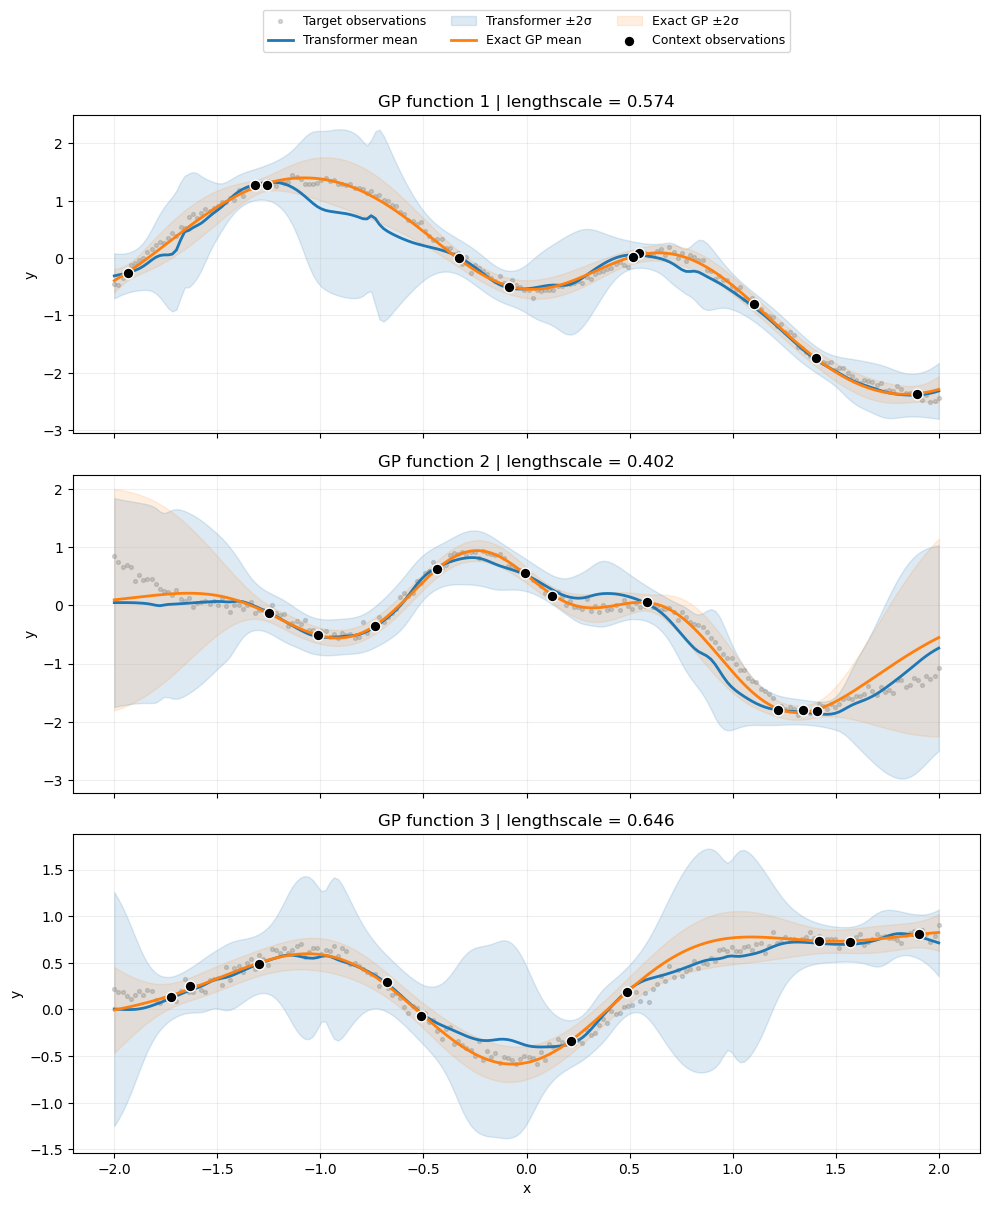

In [38]:
fig, axes = plt.subplots(
    n_examples, 1,
    figsize=(10, 4 * n_examples),
    sharex=True
)

for i, ax in enumerate(axes):

    # Convert JAX arrays to NumPy for plotting.
    x = np.asarray(xt[i])
    y = np.asarray(yt[i])

    mu_tf = np.asarray(pred_mean[i])
    std_tf = np.asarray(pred_std[i])

    mu_gp = np.asarray(gp_mean[i])
    std_gp = np.asarray(gp_std[i])

    # Target observations (not given to the transformer).
    ax.scatter(
        x, y,
        color="gray",
        s=8,
        alpha=0.3,
        label="Target observations"
    )

    # Transformer prediction and uncertainty.
    ax.plot(
        x, mu_tf,
        color="tab:blue",
        linewidth=2,
        label="Transformer mean"
    )

    ax.fill_between(
        x,
        mu_tf - 2 * std_tf,
        mu_tf + 2 * std_tf,
        color="tab:blue",
        alpha=0.15,
        label="Transformer ±2σ"
    )

    # Exact GP posterior and uncertainty.
    ax.plot(
        x, mu_gp,
        color="tab:orange",
        linewidth=2,
        label="Exact GP mean"
    )

    ax.fill_between(
        x,
        mu_gp - 2 * std_gp,
        mu_gp + 2 * std_gp,
        color="tab:orange",
        alpha=0.12,
        label="Exact GP ±2σ"
    )

    # Context observations.
    ax.scatter(
        np.asarray(xc[i]),
        np.asarray(yc[i]),
        color="black",
        edgecolor="white",
        s=60,
        zorder=5,
        label="Context observations"
    )

    ax.set_title(
        f"GP function {i+1} | lengthscale = {float(ell[i]):.3f}"
    )
    ax.set_ylabel("y")
    ax.grid(alpha=0.2)

axes[0].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.35),
    ncol=3,
    fontsize=9
)

axes[-1].set_xlabel("x")

plt.tight_layout()
plt.show()


In [39]:
# Generate independent test tasks.
xc_test, yc_test, xt_test, yt_test, ell_test = sample_tasks(
    jax.random.key(123),
    batch=1000,
    n_ctx=10,
    n_tgt=32
)

# Transformer predictions.
mean_test, log_var_test = transformer(
    params, xc_test, yc_test, xt_test
)

std_test = jnp.exp(0.5 * log_var_test)

# Exact GP predictions.
gp_mean_test, gp_cov_test = gp_posterior(
    xc_test, yc_test, xt_test, ell_test
)

gp_var_test = jnp.diagonal(
    gp_cov_test, axis1=-2, axis2=-1
)

# Evaluation metrics.
tf_mse = jnp.mean((mean_test - yt_test) ** 2)
tf_nll = gaussian_nll(mean_test, log_var_test, yt_test)

tf_coverage = jnp.mean(
    jnp.abs(yt_test - mean_test) <= 2 * std_test
)

gp_mse = jnp.mean((gp_mean_test - yt_test) ** 2)
gp_coverage = jnp.mean(
    jnp.abs(yt_test - gp_mean_test) <= 2 * jnp.sqrt(gp_var_test)
)

print(f"{'Metric':<22} {'Transformer':>14} {'Exact GP':>14}")
print("-" * 52)
print(f"{'MSE':<22} {float(tf_mse):>14.4f} {float(gp_mse):>14.4f}")
print(f"{'±2σ coverage':<22} {float(tf_coverage):>13.2%} {float(gp_coverage):>13.2%}")
print(f"{'Transformer NLL':<22} {float(tf_nll):>14.4f}")
print("\nNominal ±2σ coverage: 95.45%")


Metric                    Transformer       Exact GP
----------------------------------------------------
MSE                            0.2055         0.1447
±2σ coverage                  96.37%        95.56%
Transformer NLL                0.0902

Nominal ±2σ coverage: 95.45%


In [40]:
gp_log_var = jnp.log(gp_var_test)

gp_nll = gaussian_nll(
    gp_mean_test,
    gp_log_var,
    yt_test
)

print(f"Transformer NLL: {float(tf_nll):.4f}")
print(f"Exact GP NLL   : {float(gp_nll):.4f}")

Transformer NLL: 0.0902
Exact GP NLL   : -0.3813


---
## 3. An MLP, for comparison

Give an MLP the same job: flatten the context, zero-padded up to 30 points with a mask, and append the query
`x`. Train it the same way.

In [41]:
def make_mlp_inputs(xc, yc, xt, max_ctx=30):
    """
    Construct fixed-size inputs for the MLP regression baseline.

    Context observations are zero-padded to max_ctx points,
    with a binary mask indicating valid observations.
    Each target location is appended as a separate query.

    Args:
        xc, yc: Context inputs and observations, (batch, n_ctx).
        xt: Target locations, (batch, n_tgt).
        max_ctx: Maximum number of context points.

    Returns:
        MLP inputs, shape (batch, n_tgt, 3 * max_ctx + 1).
    """
    batch, n_ctx = xc.shape
    n_tgt = xt.shape[1]

    assert n_ctx <= max_ctx

    # Pad context coordinates and observations with zeros.
    pad_width = ((0, 0), (0, max_ctx - n_ctx))

    xc_pad = jnp.pad(xc, pad_width)
    yc_pad = jnp.pad(yc, pad_width)

    # Mask: 1 for real observations, 0 for padding.
    mask = jnp.pad(jnp.ones_like(xc), pad_width)

    # Combine each context point's x, y, and mask.
    context = jnp.stack(
        [xc_pad, yc_pad, mask], axis=-1
    )

    # Flatten the context into one fixed-size vector.
    context = context.reshape(batch, 3 * max_ctx)

    # Repeat the context vector for each target query.
    context = jnp.broadcast_to(
        context[:, None, :],
        (batch, n_tgt, 3 * max_ctx)
    )

    # Append the target x-coordinate.
    return jnp.concatenate(
        [context, xt[..., None]], axis=-1
    )


In [42]:
# Test mlp inputs
xc, yc, xt, yt, ell = sample_tasks(
    jax.random.key(0),
    batch=8,
    n_ctx=10,
    n_tgt=32
)

mlp_inputs = make_mlp_inputs(xc, yc, xt)

print("Context shape:", xc.shape)
print("Target shape :", xt.shape)
print("MLP input shape:", mlp_inputs.shape)


Context shape: (8, 10)
Target shape : (8, 32)
MLP input shape: (8, 32, 91)


In [43]:
def init_mlp_baseline(key, max_ctx=30, d_hidden=256):
    """
    Initialize a fully connected MLP for GP regression.

    Architecture:
        (3 * max_ctx + 1) -> d_hidden -> d_hidden -> 2

    Returns:
        Dictionary containing three linear layers.
    """
    keys = jax.random.split(key, 3)
    d_input = 3 * max_ctx + 1

    def init_layer(k, fan_in, fan_out):
        std = jnp.sqrt(2.0 / (fan_in + fan_out))
        return {
            "W": jax.random.normal(
                k, (fan_in, fan_out)
            ) * std,
            "b": jnp.zeros((fan_out,))
        }

    return {
        "layer1": init_layer(keys[0], d_input, d_hidden),
        "layer2": init_layer(keys[1], d_hidden, d_hidden),
        "head": init_layer(keys[2], d_hidden, 2)
    }


In [45]:
def mlp_baseline(params, xc, yc, xt, max_ctx=30):
    """
    Predict target means and log-variances using a fully
    connected MLP conditioned on flattened context points.

    Args:
        params: MLP baseline parameters.
        xc, yc: Context inputs and observations.
        xt: Target input locations.
        max_ctx: Maximum number of context observations.

    Returns:
        mean: Predicted means, (batch, n_tgt).
        log_var: Predicted log-variances, (batch, n_tgt).
    """
    # Prepare fixed-size input vectors.
    h = make_mlp_inputs(xc, yc, xt, max_ctx)

    # First hidden layer.
    p = params["layer1"]
    h = jax.nn.gelu(h @ p["W"] + p["b"])

    # Second hidden layer.
    p = params["layer2"]
    h = jax.nn.gelu(h @ p["W"] + p["b"])

    # Output projection.
    p = params["head"]
    out = h @ p["W"] + p["b"]

    mean = out[..., 0]
    log_var = out[..., 1]

    return mean, log_var


In [46]:
# Test mlp baseline
mlp_params = init_mlp_baseline(jax.random.key(1))

mean, log_var = mlp_baseline(
    mlp_params, xc, yc, xt
)

print("Mean shape:", mean.shape)
print("Log-variance shape:", log_var.shape)
print("All outputs finite:",
      bool(jnp.all(jnp.isfinite(mean)) &
           jnp.all(jnp.isfinite(log_var))))


Mean shape: (8, 32)
Log-variance shape: (8, 32)
All outputs finite: True


In [47]:
def mlp_loss_fn(params, xc, yc, xt, yt):
    """
    Compute Gaussian NLL for the MLP baseline.
    """
    mean, log_var = mlp_baseline(params, xc, yc, xt)
    return gaussian_nll(mean, log_var, yt)

In [48]:
# Training configuration
mlp_learning_rate = 3e-4
mlp_batch_size = 32
mlp_n_steps = 5000

# Initialize parameters and optimizer.
mlp_key = jax.random.key(10)
mlp_key, init_key = jax.random.split(mlp_key)

mlp_params = init_mlp_baseline(init_key)

mlp_optimizer = optax.adam(mlp_learning_rate)
mlp_opt_state = mlp_optimizer.init(mlp_params)

In [49]:
@jax.jit
def mlp_train_step(params, opt_state, xc, yc, xt, yt):
    loss, grads = jax.value_and_grad(mlp_loss_fn)(
        params, xc, yc, xt, yt
    )

    updates, opt_state = mlp_optimizer.update(
        grads, opt_state, params
    )

    params = optax.apply_updates(params, updates)

    return params, opt_state, loss

In [50]:
mlp_loss_history = []

for step in range(mlp_n_steps):

    mlp_key, k_ctx, k_data = jax.random.split(
        mlp_key, 3
    )

    n_ctx = int(jax.random.randint(k_ctx, (), 3, 31))

    xc, yc, xt, yt, ell = sample_tasks(
        k_data,
        batch=mlp_batch_size,
        n_ctx=n_ctx,
        n_tgt=32
    )

    mlp_params, mlp_opt_state, loss = mlp_train_step(
        mlp_params, mlp_opt_state, xc, yc, xt, yt
    )

    mlp_loss_history.append(float(loss))

    if (step + 1) % 500 == 0:
        print(
            f"Step {step+1:4d}/{mlp_n_steps} | "
            f"Loss = {float(loss):.4f}"
        )


Step  500/5000 | Loss = 1.3020
Step 1000/5000 | Loss = 1.2050
Step 1500/5000 | Loss = 1.2075
Step 2000/5000 | Loss = 1.0659
Step 2500/5000 | Loss = 0.9913
Step 3000/5000 | Loss = 1.1546
Step 3500/5000 | Loss = 1.1942
Step 4000/5000 | Loss = 1.1006
Step 4500/5000 | Loss = 1.0191
Step 5000/5000 | Loss = 1.0579


In [51]:
xc_test, yc_test, xt_test, yt_test, ell_test = sample_tasks(
    jax.random.key(1234),
    batch=1000,
    n_ctx=10,
    n_tgt=32
)

# Transformer predictions.
tf_mean, tf_log_var = transformer(
    params, xc_test, yc_test, xt_test
)

# MLP predictions.
mlp_mean, mlp_log_var = mlp_baseline(
    mlp_params, xc_test, yc_test, xt_test
)

# Exact GP predictions.
gp_mean, gp_cov = gp_posterior(
    xc_test, yc_test, xt_test, ell_test
)

# Compute MSE.
tf_mse = jnp.mean((tf_mean - yt_test) ** 2)
mlp_mse = jnp.mean((mlp_mean - yt_test) ** 2)
gp_mse = jnp.mean((gp_mean - yt_test) ** 2)

print(f"Transformer MSE : {float(tf_mse):.4f}")
print(f"MLP MSE         : {float(mlp_mse):.4f}")
print(f"Exact GP MSE    : {float(gp_mse):.4f}")


Transformer MSE : 0.2002
MLP MSE         : 0.5922
Exact GP MSE    : 0.1359


---
## 4. Results 

- **Test error against the number of context points**, from 3 to 80, log-log, for the transformer, the MLP,
  and `gp_posterior` with the true lengthscale
- What happens to each model's predictions when you **shuffle the context points**?
- Plot something I didn't ask for!

- **Test error against the number of context points**, from 3 to 80, log-log, for the transformer, the MLP,
  and `gp_posterior` with the true lengthscale

In [52]:
# Evaluation configuration
n_ctx_values = np.unique(
    np.round(np.geomspace(3, 80, 15)).astype(int)
)

test_batch = 512
n_tgt = 32

# Store test errors.
tf_errors = []
mlp_errors = []
gp_errors = []
zero_errors = []

for n_ctx in n_ctx_values:

    # Use a fixed, distinct random seed for each context size.
    test_key = jax.random.key(1000 + int(n_ctx))

    # Generate independent test tasks.
    xc, yc, xt, yt, ell = sample_tasks(
        test_key,
        batch=test_batch,
        n_ctx=int(n_ctx),
        n_tgt=n_tgt
    )

    # Transformer predictions.
    tf_mean, _ = transformer(params, xc, yc, xt)

    tf_mse = jnp.mean((tf_mean - yt) ** 2)

    # Exact GP predictions.
    gp_mean, _ = gp_posterior(xc, yc, xt, ell)

    gp_mse = jnp.mean((gp_mean - yt) ** 2)

    # Zero predictor baseline.
    zero_mse = jnp.mean(yt ** 2)

    # MLP only supports up to 30 context points.
    if n_ctx <= 30:
        mlp_mean, _ = mlp_baseline(
            mlp_params, xc, yc, xt
        )
        mlp_mse = float(jnp.mean((mlp_mean - yt) ** 2))
    else:
        mlp_mse = np.nan

    # Record results.
    tf_errors.append(float(tf_mse))
    mlp_errors.append(mlp_mse)
    gp_errors.append(float(gp_mse))
    zero_errors.append(float(zero_mse))

    print(
        f"n_ctx={n_ctx:2d} | "
        f"Transformer={float(tf_mse):.4f} | "
        f"MLP={mlp_mse:.4f} | "
        f"GP={float(gp_mse):.4f}"
    )


n_ctx= 3 | Transformer=0.5562 | MLP=0.7185 | GP=0.4833
n_ctx= 4 | Transformer=0.4723 | MLP=0.7005 | GP=0.3804
n_ctx= 5 | Transformer=0.4512 | MLP=0.7229 | GP=0.3843
n_ctx= 6 | Transformer=0.3642 | MLP=0.6663 | GP=0.2890
n_ctx= 8 | Transformer=0.2579 | MLP=0.6321 | GP=0.1916
n_ctx=10 | Transformer=0.2040 | MLP=0.5940 | GP=0.1393
n_ctx=12 | Transformer=0.1602 | MLP=0.6024 | GP=0.0996
n_ctx=15 | Transformer=0.1091 | MLP=0.5959 | GP=0.0663
n_ctx=20 | Transformer=0.0643 | MLP=0.5432 | GP=0.0343
n_ctx=25 | Transformer=0.0470 | MLP=0.5566 | GP=0.0209
n_ctx=31 | Transformer=0.0284 | MLP=nan | GP=0.0125
n_ctx=40 | Transformer=0.0229 | MLP=nan | GP=0.0078
n_ctx=50 | Transformer=0.0156 | MLP=nan | GP=0.0051
n_ctx=63 | Transformer=0.0122 | MLP=nan | GP=0.0036
n_ctx=80 | Transformer=0.0113 | MLP=nan | GP=0.0033


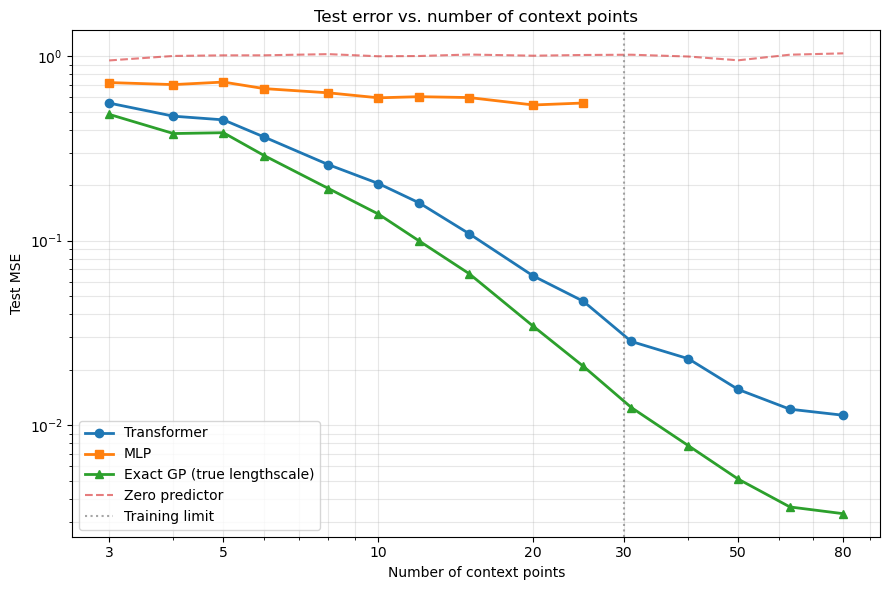

In [53]:
plt.figure(figsize=(9, 6))

plt.plot(
    n_ctx_values, tf_errors,
    "o-", linewidth=2,
    label="Transformer"
)

plt.plot(
    n_ctx_values, mlp_errors,
    "s-", linewidth=2,
    label="MLP"
)

plt.plot(
    n_ctx_values, gp_errors,
    "^-", linewidth=2,
    label="Exact GP (true lengthscale)"
)

plt.plot(
    n_ctx_values, zero_errors,
    "--", alpha=0.6,
    label="Zero predictor"
)

# Logarithmic axes.
plt.xscale("log")
plt.yscale("log")

plt.xlabel("Number of context points")
plt.ylabel("Test MSE")
plt.title("Test error vs. number of context points")

plt.xticks(
    [3, 5, 10, 20, 30, 50, 80],
    [3, 5, 10, 20, 30, 50, 80]
)

plt.axvline(
    30, color="gray", linestyle=":",
    alpha=0.7, label="Training limit"
)

plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()


- What happens to each model's predictions when you **shuffle the context points**?

In [55]:
# Fixed test set.
batch = 1000
n_ctx = 10
n_tgt = 32
n_shuffles = 20

xc, yc, xt, yt, ell = sample_tasks(
    jax.random.key(1234),
    batch=batch,
    n_ctx=n_ctx,
    n_tgt=n_tgt
)

# Original predictions.
tf_mean, tf_log_var = transformer(params, xc, yc, xt)
mlp_mean, mlp_log_var = mlp_baseline(mlp_params, xc, yc, xt)

# Original test MSE.
tf_mse = float(jnp.mean((tf_mean - yt) ** 2))
mlp_mse = float(jnp.mean((mlp_mean - yt) ** 2))

print(f"Original transformer MSE: {tf_mse:.4f}")
print(f"Original MLP MSE        : {mlp_mse:.4f}")


Original transformer MSE: 0.2002
Original MLP MSE        : 0.5922


In [56]:
# Store results for each random permutation.
tf_diffs = []
mlp_diffs = []
tf_mses = []
mlp_mses = []

key = jax.random.key(42)

for i in range(n_shuffles):

    key, shuffle_key = jax.random.split(key)

    # Independent random permutation for every GP function.
    perm = jnp.argsort(
        jax.random.uniform(shuffle_key, (batch, n_ctx)),
        axis=1
    )

    # Shuffle context x and y using the same indices.
    xc_shuffle = jnp.take_along_axis(xc, perm, axis=1)
    yc_shuffle = jnp.take_along_axis(yc, perm, axis=1)

    # Predictions using shuffled context.
    tf_mean_shuffle, _ = transformer(
        params, xc_shuffle, yc_shuffle, xt
    )

    mlp_mean_shuffle, _ = mlp_baseline(
        mlp_params, xc_shuffle, yc_shuffle, xt
    )

    # Mean absolute change relative to original predictions.
    tf_diff = jnp.mean(jnp.abs(tf_mean_shuffle - tf_mean))
    mlp_diff = jnp.mean(jnp.abs(mlp_mean_shuffle - mlp_mean))

    # Test MSE after shuffling.
    tf_mse_shuffle = jnp.mean((tf_mean_shuffle - yt) ** 2)
    mlp_mse_shuffle = jnp.mean((mlp_mean_shuffle - yt) ** 2)

    tf_diffs.append(float(tf_diff))
    mlp_diffs.append(float(mlp_diff))

    tf_mses.append(float(tf_mse_shuffle))
    mlp_mses.append(float(mlp_mse_shuffle))


In [57]:
print("Mean absolute change in predictions:")
print(f"Transformer: {np.mean(tf_diffs):.8f}")
print(f"MLP        : {np.mean(mlp_diffs):.8f}")

print("\nTest MSE:")
print(f"{'Model':<15} {'Original':>12} {'Shuffled':>12}")
print("-" * 41)

print(
    f"{'Transformer':<15} "
    f"{tf_mse:>12.4f} "
    f"{np.mean(tf_mses):>12.4f}"
)

print(
    f"{'MLP':<15} "
    f"{mlp_mse:>12.4f} "
    f"{np.mean(mlp_mses):>12.4f}"
)


Mean absolute change in predictions:
Transformer: 0.00000043
MLP        : 0.07643800

Test MSE:
Model               Original     Shuffled
-----------------------------------------
Transformer           0.2002       0.2002
MLP                   0.5922       0.5905


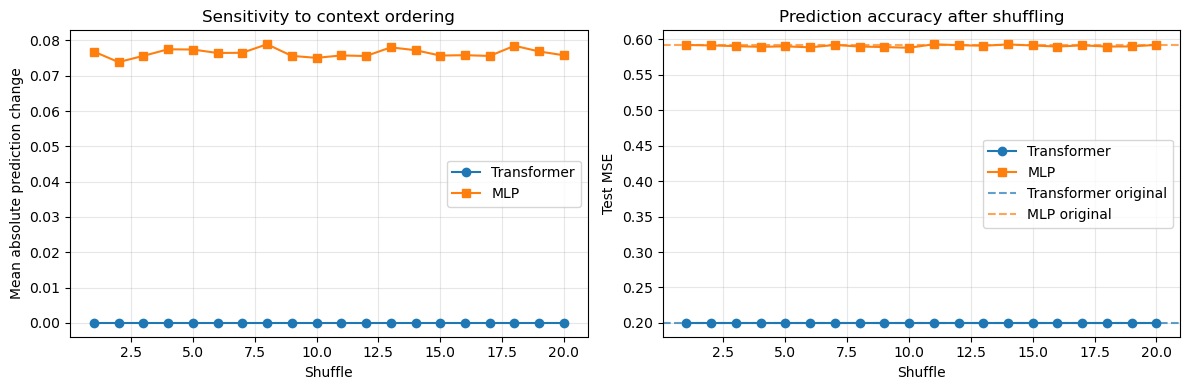

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

shuffles = np.arange(1, n_shuffles + 1)

# Prediction sensitivity.
axes[0].plot(
    shuffles, tf_diffs, "o-",
    label="Transformer"
)
axes[0].plot(
    shuffles, mlp_diffs, "s-",
    label="MLP"
)

axes[0].set_xlabel("Shuffle")
axes[0].set_ylabel("Mean absolute prediction change")
axes[0].set_title("Sensitivity to context ordering")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Test MSE.
axes[1].plot(
    shuffles, tf_mses, "o-",
    label="Transformer"
)
axes[1].plot(
    shuffles, mlp_mses, "s-",
    label="MLP"
)

axes[1].axhline(
    tf_mse, color="tab:blue",
    linestyle="--", alpha=0.7,
    label="Transformer original"
)

axes[1].axhline(
    mlp_mse, color="tab:orange",
    linestyle="--", alpha=0.7,
    label="MLP original"
)

axes[1].set_xlabel("Shuffle")
axes[1].set_ylabel("Test MSE")
axes[1].set_title("Prediction accuracy after shuffling")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


Shuffling context observations produced a negligible change in the transformer's predictions (mean absolute difference $4.3\times10^{-7}$), confirming permutation invariance up to numerical precision. In contrast, the flattened MLP showed a mean absolute prediction change of \(0.0764\), demonstrating sensitivity to context ordering. Nevertheless, the MLP's test MSE remained approximately constant (0.5922 versus 0.5905), likely because it was trained on randomly ordered context observations. This illustrates the distinction between architectural permutation invariance and approximate robustness to permutations learned from data.

- Uncertainty calibration

In [61]:
# Fixed test dataset for uncertainty evaluation.
xc_test, yc_test, xt_test, yt_test, ell_test = sample_tasks(
    jax.random.key(1234),
    batch=1000,
    n_ctx=10,
    n_tgt=32
)

# Transformer predictions.
tf_mean, tf_log_var = transformer(
    params, xc_test, yc_test, xt_test
)
tf_std = jnp.exp(0.5 * tf_log_var)

# MLP predictions.
mlp_mean, mlp_log_var = mlp_baseline(
    mlp_params, xc_test, yc_test, xt_test
)
mlp_std = jnp.exp(0.5 * mlp_log_var)

# Exact GP posterior with the true lengthscale.
gp_mean, gp_cov = gp_posterior(
    xc_test, yc_test, xt_test, ell_test
)

gp_var = jnp.diagonal(
    gp_cov, axis1=-2, axis2=-1
)
gp_std = jnp.sqrt(jnp.maximum(gp_var, 1e-12))

# Standardized residuals.
tf_z = (yt_test - tf_mean) / tf_std
mlp_z = (yt_test - mlp_mean) / mlp_std
gp_z = (yt_test - gp_mean) / gp_std


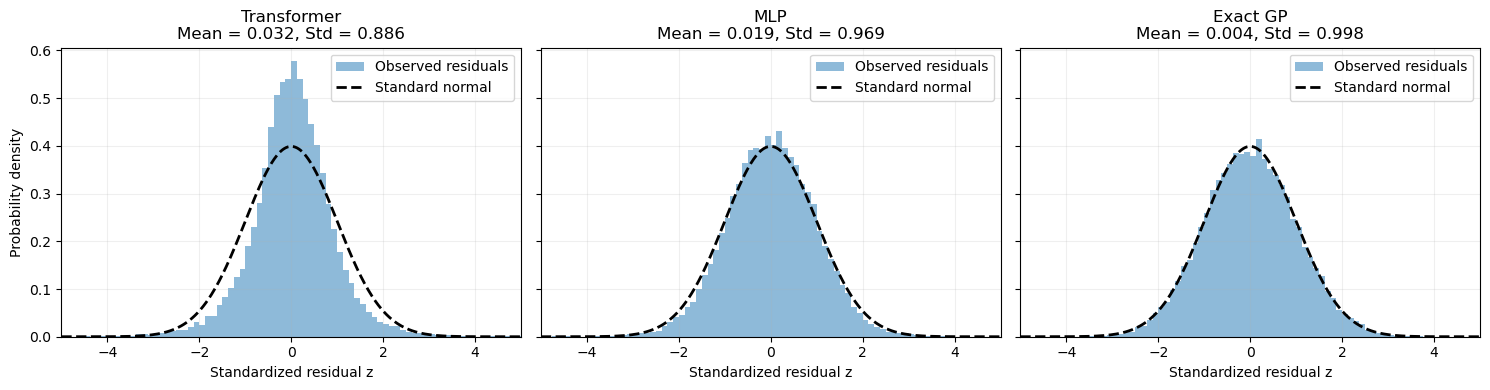

In [62]:
from scipy.stats import norm

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

models = [
    ("Transformer", tf_z),
    ("MLP", mlp_z),
    ("Exact GP", gp_z)
]

z_grid = np.linspace(-5, 5, 500)

for ax, (name, z) in zip(axes, models):
    z = np.asarray(z).ravel()

    # Histogram of standardized residuals.
    ax.hist(
        z,
        bins=80,
        range=(-5, 5),
        density=True,
        alpha=0.5,
        label="Observed residuals"
    )

    # Ideal standard normal density.
    ax.plot(
        z_grid,
        norm.pdf(z_grid),
        "k--",
        linewidth=2,
        label="Standard normal"
    )

    ax.set_title(
        f"{name}\n"
        f"Mean = {z.mean():.3f}, Std = {z.std():.3f}"
    )
    ax.set_xlabel("Standardized residual z")
    ax.set_xlim(-5, 5)
    ax.grid(alpha=0.2)
    ax.legend()

axes[0].set_ylabel("Probability density")

plt.tight_layout()
plt.show()


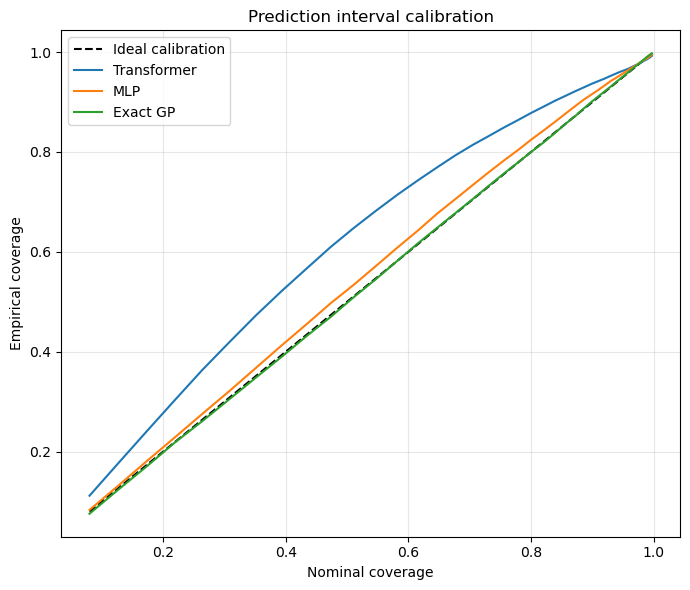

In [63]:
# Interval thresholds in units of standard deviation.
k_values = np.linspace(0.1, 3, 50)

# Theoretical Gaussian coverage.
nominal = 2 * norm.cdf(k_values) - 1

def empirical_coverage(z, k_values):
    z = np.asarray(z).ravel()
    return np.array([
        np.mean(np.abs(z) <= k)
        for k in k_values
    ])

tf_coverage = empirical_coverage(tf_z, k_values)
mlp_coverage = empirical_coverage(mlp_z, k_values)
gp_coverage = empirical_coverage(gp_z, k_values)

plt.figure(figsize=(7, 6))

plt.plot(nominal, nominal, "k--", label="Ideal calibration")
plt.plot(nominal, tf_coverage, label="Transformer")
plt.plot(nominal, mlp_coverage, label="MLP")
plt.plot(nominal, gp_coverage, label="Exact GP")

plt.xlabel("Nominal coverage")
plt.ylabel("Empirical coverage")
plt.title("Prediction interval calibration")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [64]:
print(
    f"{'Model':<15} {'Mean(z)':>10} {'Std(z)':>10} "
    f"{'±1σ':>10} {'±2σ':>10}"
)
print("-" * 60)

for name, z in models:
    z = np.asarray(z).ravel()

    print(
        f"{name:<15} "
        f"{z.mean():>10.3f} "
        f"{z.std():>10.3f} "
        f"{np.mean(np.abs(z) <= 1):>10.2%} "
        f"{np.mean(np.abs(z) <= 2):>10.2%}"
    )

print("-" * 60)
print(f"{'Ideal Gaussian':<15} {'0.000':>10} {'1.000':>10} "
      f"{'68.27%':>10} {'95.45%':>10}")


Model              Mean(z)     Std(z)        ±1σ        ±2σ
------------------------------------------------------------
Transformer          0.032      0.886     79.75%     96.45%
MLP                  0.019      0.969     71.20%     96.06%
Exact GP             0.004      0.998     68.34%     95.50%
------------------------------------------------------------
Ideal Gaussian       0.000      1.000     68.27%     95.45%


The standardized-residual analysis reveals that the transformer systematically overestimates predictive uncertainty, with a standardized-residual standard deviation of **0.886** and $\pm 1\sigma$ coverage of **79.75%**, compared with the nominal **68.27%**. Although its $\pm 2\sigma$ coverage of **96.45%** is close to the expected **95.45%**, the full calibration curve shows substantial deviations at intermediate confidence levels.

The MLP baseline, despite substantially higher prediction MSE, exhibits better uncertainty calibration (standardized-residual standard deviation of **0.969**). The exact GP benchmark is nearly perfectly calibrated, as expected under the known data-generating model.


---
## 5. Flow matching

Now generate posteriors over functions. Target tokens carry a noisy value $y_t$ instead of 0, the time $t$ is embedded and added
to every token, and the head outputs one velocity per target. Same network as before.

Train on the straight path from noise $\epsilon \sim \mathcal{N}(0, 1)$ to data:

$$y_t = (1-t)\,\epsilon + t\,y, \qquad \mathcal{L} = \big\| v_\theta(y_t, t \mid \text{context}) - (y - \epsilon) \big\|^2$$

Sample by integrating $dy/dt = v_\theta$ from $t=0$ to $1$ with Euler, 50 steps.